# Capstone Project 1 
## Project Name : Predictive Maintenance 
## Created By : Samruddhi Mulmule

### Problem Statement:
The goal of this project is to build a machine learning model to predict whether a machine is likely to experience a failure based on real-time sensor data. This is crucial for implementing predictive maintenance strategies, which help in reducing downtime, improving efficiency, and minimizing operational costs. Candidate will analyze the dataset, explore relationships between variables, and develop a classification model to predict the "Target" variable, which indicates whether a machine will fail or not.

### Objective: 
Build a classification model using classification algorithms and compare their performances to predict whether a machine is likely to experience a failure or not.

### Dataset Overview:
The dataset consists of  9 columns. Each row represents a machine’s operational status under specific conditions. The task is to use the provided variables to predict the likelihood of a machine failure.

### Variable Descriptions:
|Column Name |	Description |	Data Type|
|----------|--------|--------|
|UDI	| Unique identifier for each machine record.	| Integer (ID)|
|Product ID	| Identifier for the machine’s product category.	| String (Alphanumeric)|
|Type	| Machine type - Low (L), Medium (M), High (H).	| Categorical|
|Air temperature [K]	| Temperature of the surrounding air (Kelvin).	| Float (Continuous)|
|Process temperature [K]	| Temperature during the manufacturing process (Kelvin).	| Float (Continuous)|
|Rotational speed [rpm]	| Speed of the machine’s rotation (Revolutions per minute).	| Integer (Continuous)|
|Torque [Nm]	| Torque produced by the machine (Newton-meters).	| Float (Continuous)|
|Tool wear [min]	| Amount of wear on the tool (Minutes of usage).	| Integer (Continuous)|
|Target	| Machine failure indicator (0: No Failure, 1: Failure).	| Binary (0/1)|





## Solution:

### 1. Importing Libraries

In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     cross_val_predict, RandomizedSearchCV, learning_curve)
from sklearn.preprocessing import RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.inspection import permutation_importance

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier, AdaBoostClassifier)
from sklearn.svm import SVC
from xgboost import XGBClassifier

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve,
                             precision_recall_curve)
import joblib

RANDOM_STATE = 42
sns.set_style('whitegrid')
pd.set_option('display.max_columns', 50)

### 2. Loading Dataset

In [3]:
df=pd.read_csv("predictive_maintenance.csv")

In [4]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target
0,1,M14860,M,298.1,308.6,1551,42.8,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0


### Standardizing Column Names

In [5]:
df = df.rename(columns={
    'Product ID': 'Product_ID',
    'Air temperature [K]': 'Air_temp',
    'Process temperature [K]': 'Process_temp',
    'Rotational speed [rpm]': 'Rot_speed',
    'Torque [Nm]': 'Torque',
    'Tool wear [min]': 'Tool_wear'})

In [6]:
df.head()

,UDI,Product_ID,Type,Air_temp,Process_temp,Rot_speed,Torque,Tool_wear,Target
0,1,M14860,M,298.1,308.6,1551,42.8,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0


### 3. Dataset Inspection & Cleaning

In [8]:
df.shape

(10000, 9)

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   UDI           10000 non-null  int64  
 1   Product_ID    10000 non-null  str    
 2   Type          10000 non-null  str    
 3   Air_temp      10000 non-null  float64
 4   Process_temp  10000 non-null  float64
 5   Rot_speed     10000 non-null  int64  
 6   Torque        10000 non-null  float64
 7   Tool_wear     10000 non-null  int64  
 8   Target        10000 non-null  int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 771.6 KB


In [10]:
df.isnull().sum()

UDI             0
Product_ID      0
Type            0
Air_temp        0
Process_temp    0
Rot_speed       0
Torque          0
Tool_wear       0
Target          0
dtype: int64

No Null values found

In [12]:
df.duplicated().sum()

np.int64(0)

No duplicates found

In [14]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air_temp,10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process_temp,10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rot_speed,10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque,10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool_wear,10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Target,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0


In [16]:
df.nunique()

UDI             10000
Product_ID      10000
Type                3
Air_temp           93
Process_temp       82
Rot_speed         941
Torque            577
Tool_wear         246
Target              2
dtype: int64

Column UDI and Product_ID seems to be unique identifiers of rows which has no role in predictive analysis, so we can drop them in future.

### 4. Exploratory Data Analysis

In [17]:
df['Target'].value_counts()

Target
0    9661
1     339
Name: count, dtype: int64

Data seems to be highly imbalanced so we need to focus on recall, precision, F1 and PR-AUC. And treat the imbalance.

#### Target Distribution

        count  percent
Target                
0        9661    96.61
1         339     3.39


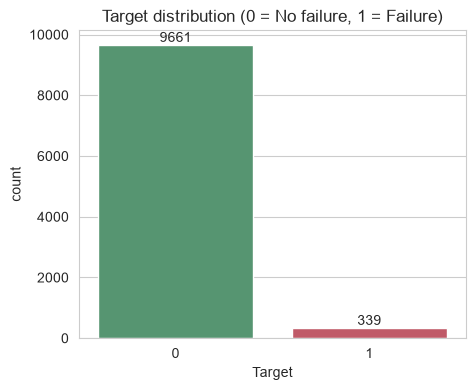

In [18]:
counts = df['Target'].value_counts()
pct = df['Target'].value_counts(normalize=True) * 100
print(pd.DataFrame({'count': counts, 'percent': pct.round(2)}))

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x='Target', data=df, ax=ax, palette=['#4C9F70', '#D1495B'])
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')
ax.set_title('Target distribution (0 = No failure, 1 = Failure)')
plt.show()

#### Machine Type Vs Failure

      machines  failures  failure_rate
Type                                  
H         1003        21      0.020937
L         6000       235      0.039167
M         2997        83      0.027694


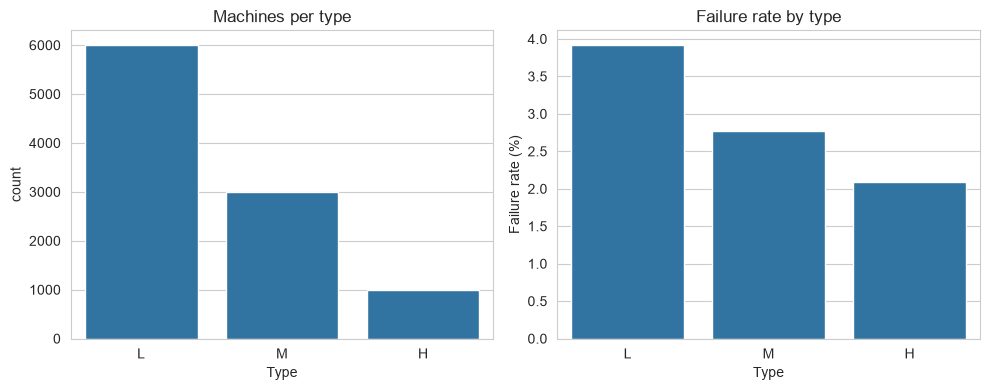

In [19]:
type_summary = df.groupby('Type')['Target'].agg(['count', 'sum', 'mean'])
type_summary.columns = ['machines', 'failures', 'failure_rate']
print(type_summary)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x='Type', data=df, order=['L', 'M', 'H'], ax=axes[0])
axes[0].set_title('Machines per type')
sns.barplot(x=type_summary.index, y=type_summary['failure_rate'] * 100,
            order=['L', 'M', 'H'], ax=axes[1])
axes[1].set_ylabel('Failure rate (%)')
axes[1].set_title('Failure rate by type')
plt.tight_layout(); plt.show()

#### Distbribution of Numerical Features

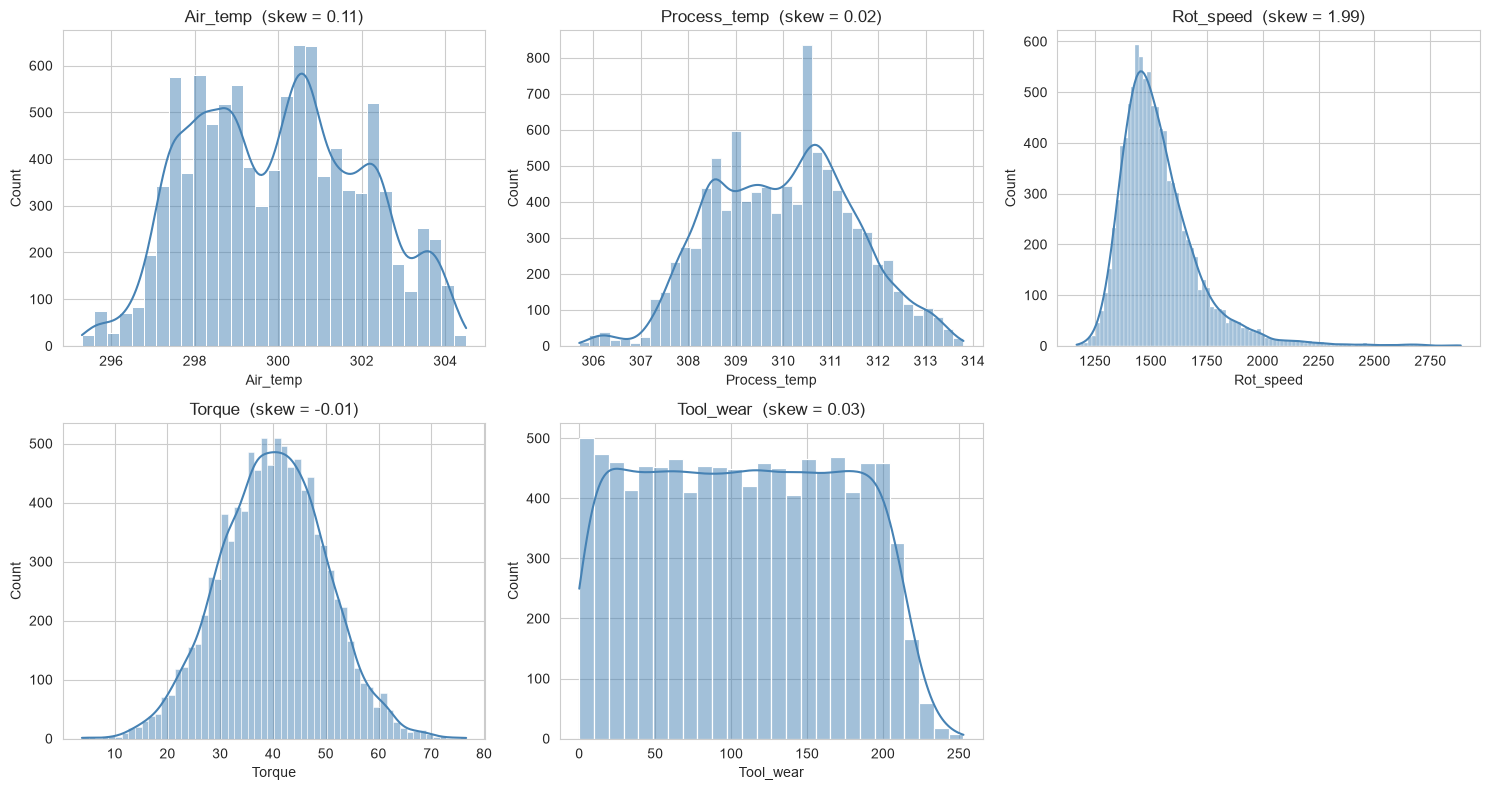

In [20]:
num_cols = ['Air_temp', 'Process_temp', 'Rot_speed', 'Torque', 'Tool_wear']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], kde=True, ax=ax, color='steelblue')
    ax.set_title(f'{col}  (skew = {df[col].skew():.2f})')
axes.ravel()[-1].axis('off')
plt.tight_layout(); plt.show()

#### Box Plots for Failed Vs Non Failed Machines

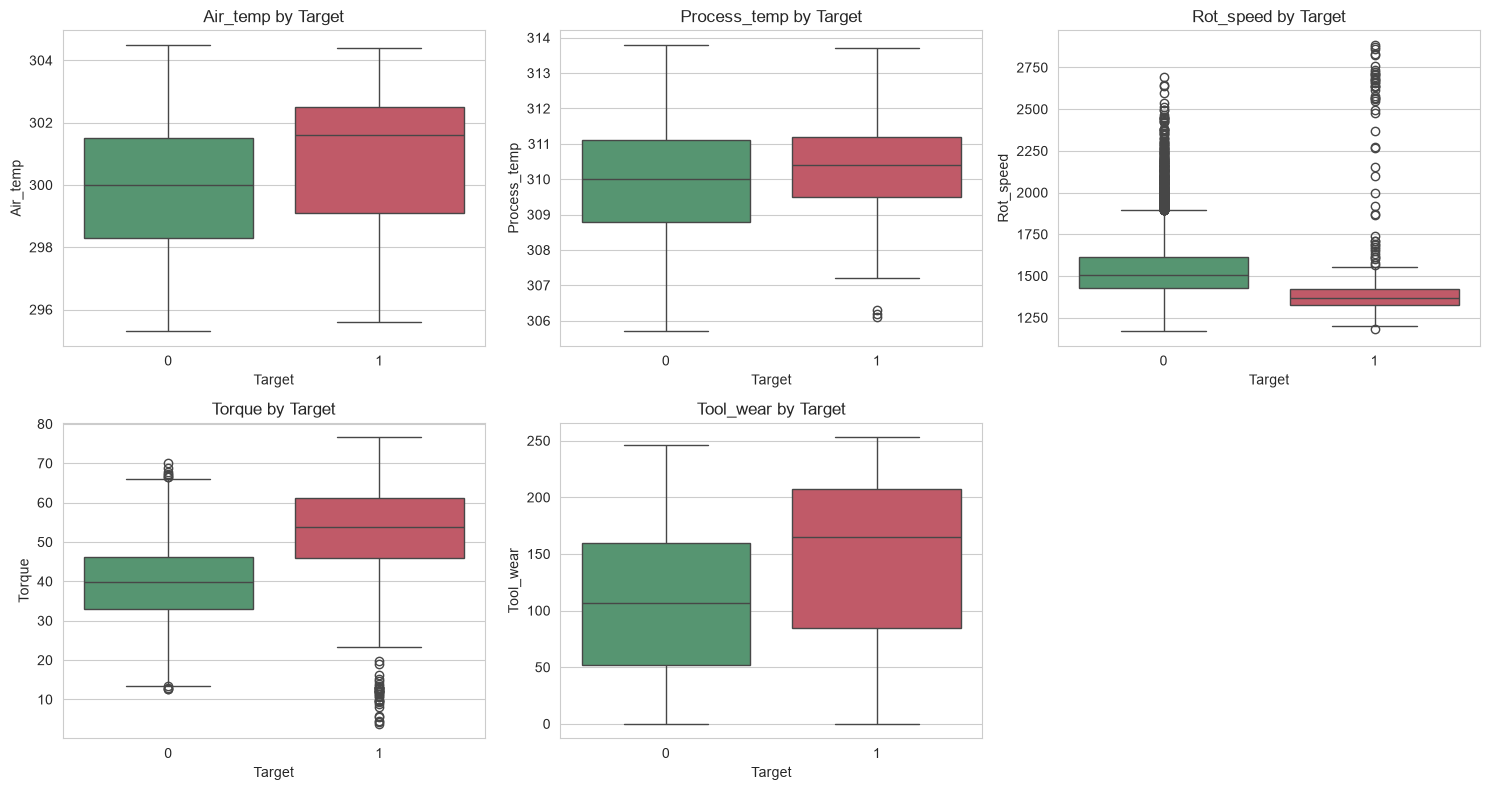

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(x='Target', y=col, data=df, ax=ax, palette=['#4C9F70', '#D1495B'])
    ax.set_title(f'{col} by Target')
axes.ravel()[-1].axis('off')
plt.tight_layout(); plt.show()

Failed machines seem to have more number of outliers, they also have higher torque, high tool_wear and lesser rot_speed as compared to non failed machines

#### Correlation Analysis

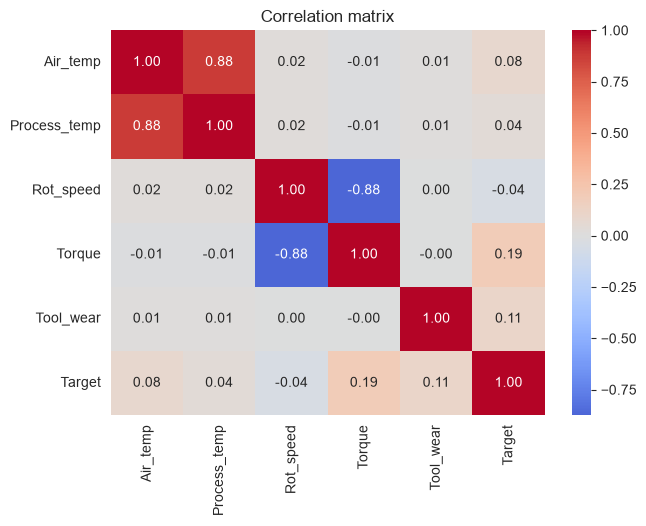

In [22]:
corr = df[num_cols + ['Target']].corr()
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlation matrix')
plt.show()

`Air_temp` and `Process_temp` are strongly correlated (about 0.88), and `Rot_speed` and `Torque` are strongly negatively correlated (about -0.88). This is the expected behaviour of the machine

### 5. Feature engineering
Creating features that capture physically meaningful stress on the machine:
- `Temp_diff` = process temperature − air temperature (heat dissipation)
- `Power` = torque × rotational speed in rad/s (mechanical power)
- `Torque_wear` = torque × tool wear (overstrain indicator)

These are calculated from the raw values before any transformation.

In [23]:
df['Temp_diff'] = df['Process_temp'] - df['Air_temp']
df['Power'] = df['Torque'] * df['Rot_speed'] * 2 * np.pi / 60
df['Torque_wear'] = df['Torque'] * df['Tool_wear']

new_feats = ['Temp_diff', 'Power', 'Torque_wear']
print(df[new_feats + ['Target']].corr()['Target'].drop('Target').round(3))
df[new_feats].describe().T

Temp_diff     -0.112
Power          0.176
Torque_wear    0.190
Name: Target, dtype: float64


,count,mean,std,min,25%,50%,75%,max
Temp_diff,10000.0,10.000630,1.001094,7.60000,9.300000,9.800000,11.000000,12.100000
Power,10000.0,6279.744953,1067.418295,1148.44061,5561.184484,6271.027344,7003.002724,10469.923005
Torque_wear,10000.0,4314.664550,2826.567692,0.00000,1963.650000,4012.950000,6279.000000,16497.000000


New features have very little correlation with target and have better varible distribution

### 6. Skewness Check & Transformation

In [24]:
cont_cols = num_cols + new_feats
skew_before = df[cont_cols].skew().sort_values(ascending=False)
print(skew_before.round(3))

Rot_speed       1.993
Torque_wear     0.470
Air_temp        0.114
Tool_wear       0.027
Process_temp    0.015
Power           0.008
Torque         -0.010
Temp_diff      -0.072
dtype: float64


In [25]:
skewed_cols = skew_before[skew_before.abs() > 0.75].index.tolist()
print('Skewed Columns:', skewed_cols)

Skewed Columns: ['Rot_speed']


Column Rot_speed is skewed as it has 1.993 skewness value. So we will treat this skewness with `log1p` transformation

              skew_before  skew_after
Air_temp            0.114       0.114
Process_temp        0.015       0.015
Rot_speed           1.993       1.310
Torque             -0.010      -0.010
Tool_wear           0.027       0.027
Temp_diff          -0.072      -0.072
Power               0.008       0.008
Torque_wear         0.470       0.470


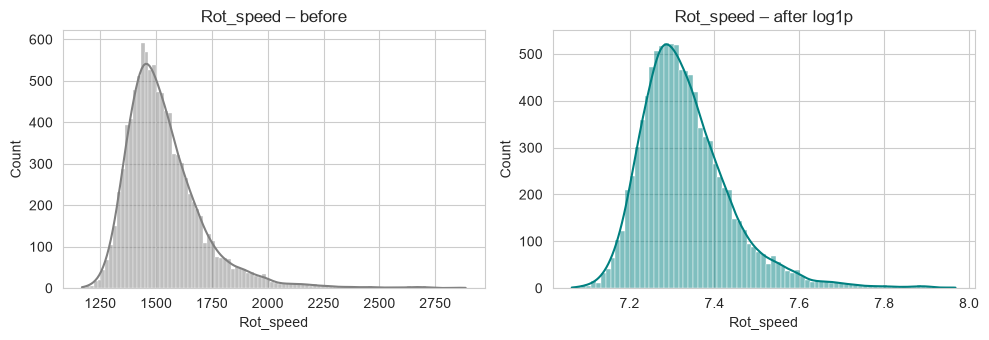

In [26]:
df_t = df.copy()
for col in skewed_cols:
    assert (df_t[col] >= 0).all()
    df_t[col] = np.log1p(df_t[col])

comparison = pd.DataFrame({'skew_before': df[cont_cols].skew(),
                           'skew_after': df_t[cont_cols].skew()}).round(3)
print(comparison)

if skewed_cols:
    fig, axes = plt.subplots(len(skewed_cols), 2, figsize=(10, 3.5 * len(skewed_cols)), squeeze=False)
    for i, col in enumerate(skewed_cols):
        sns.histplot(df[col], kde=True, ax=axes[i, 0], color='gray')
        axes[i, 0].set_title(f'{col} – before')
        sns.histplot(df_t[col], kde=True, ax=axes[i, 1], color='teal')
        axes[i, 1].set_title(f'{col} – after log1p')
    plt.tight_layout(); plt.show()

df = df_t

Log1p transformation has reduced the skeness of rot_speed column but hasn't completly removed it. Lets analyze further to see if these are genuine high rot_speed values

## 7. Outlier check & treatment
We count outliers with the IQR rule (1.5 × IQR). Before removing anything we check **whether the outliers are linked to failures**. As these outliers can be genuine values as well.

In [27]:
def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
overall_rate = df['Target'].mean() * 100
for col in cont_cols:
    lo, hi = iqr_bounds(df[col])
    mask = (df[col] < lo) | (df[col] > hi)
    rows.append({'feature': col, 'n_outliers': int(mask.sum()),
                 'pct_outliers': round(mask.mean() * 100, 2),
                 'failure_rate_in_outliers_%': round(df.loc[mask, 'Target'].mean() * 100, 2) if mask.any() else np.nan,
                 'overall_failure_rate_%': round(overall_rate, 2)})
outlier_table = pd.DataFrame(rows)
outlier_table

,feature,n_outliers,pct_outliers,failure_rate_in_outliers_%,overall_failure_rate_%
0,Air_temp,0,0.00,NaN,3.39
1,Process_temp,0,0.00,NaN,3.39
2,Rot_speed,323,3.23,10.53,3.39
3,Torque,69,0.69,89.86,3.39
4,Tool_wear,0,0.00,NaN,3.39
5,Temp_diff,0,0.00,NaN,3.39
6,Power,60,0.60,100.00,3.39
7,Torque_wear,20,0.20,100.00,3.39


We are keeping the outliers as the table above shows that for columns `Torque`, `Power` and `Torque_wear` the failure rate inside the outlier rows is far above the overall 3.4% failure rate, so those rows carry real signal. The dataset also has very few failures (~340), so deleting rows would remove valuable minority-class 

### 8. Train/test split, scaling and class-imbalance handling

In [28]:
X = df.drop(columns=['UDI', 'Product_ID', 'Target'])
X = pd.get_dummies(X, columns=['Type'], drop_first=True, dtype=int)
y = df['Target']

In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print('Train:', X_train.shape, '| failure rate: %.2f%%' % (y_train.mean() * 100))
print('Test :', X_test.shape,  '| failure rate: %.2f%%' % (y_test.mean() * 100))

Train: (8000, 10) | failure rate: 3.39%
Test : (2000, 10) | failure rate: 3.40%


Using StandardScalar and SMOTE method to scale the data and do oversampling

In [30]:
from sklearn.preprocessing import StandardScaler

_, y_smote = SMOTE(random_state=RANDOM_STATE).fit_resample(StandardScaler().fit_transform(X_train), y_train)
print('Before SMOTE:', y_train.value_counts().to_dict())
print('After SMOTE :', y_smote.value_counts().to_dict())

Before SMOTE: {0: 7729, 1: 271}
After SMOTE : {0: 7729, 1: 7729}


#### Creating Pipeline for everymodel to use scaling and SMOTE

In [32]:
def make_pipeline(model):
    return ImbPipeline([('scale', StandardScaler()),
                        ('smote', SMOTE(random_state=RANDOM_STATE)),
                        ('model', model)])


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

### 8. Creating and Comparing All Supervised ML Models

In [37]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Naive Bayes': GaussianNB(),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    'AdaBoost': AdaBoostClassifier(n_estimators=200, random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingClassifier(random_state=RANDOM_STATE),
    'SVM (RBF)': SVC(kernel='rbf', random_state=RANDOM_STATE),
    'XGBoost': XGBClassifier(n_estimators=300, learning_rate=0.1, eval_metric='logloss',
                             random_state=RANDOM_STATE, n_jobs=-1),
}

scoring = {'accuracy': 'accuracy', 'precision': 'precision', 'recall': 'recall',
           'f1': 'f1', 'roc_auc': 'roc_auc', 'pr_auc': 'average_precision'}



In [38]:
cv_rows = []
for name, model in models.items():
    res = cross_validate(make_pipeline(model), X_train, y_train, cv=cv, scoring=scoring,
                         return_train_score=True, n_jobs=-1)
    cv_rows.append({'model': name,
                    'cv_accuracy': res['test_accuracy'].mean(),
                    'cv_precision': res['test_precision'].mean(),
                    'cv_recall': res['test_recall'].mean(),
                    'cv_f1': res['test_f1'].mean(),
                    'cv_f1_std': res['test_f1'].std(),
                    'cv_roc_auc': res['test_roc_auc'].mean(),
                    'cv_pr_auc': res['test_pr_auc'].mean(),
                    'train_f1': res['train_f1'].mean()})
    print(f'done: {name}')

cv_results = pd.DataFrame(cv_rows).set_index('model').sort_values('cv_f1', ascending=False)
cv_results.round(3)

done: Logistic Regression
done: KNN
done: Naive Bayes
done: Decision Tree
done: Random Forest
done: AdaBoost
done: Gradient Boosting
done: SVM (RBF)
done: XGBoost


,cv_accuracy,cv_precision,cv_recall,cv_f1,cv_f1_std,cv_roc_auc,cv_pr_auc,train_f1
model,,,,,,,,
XGBoost,0.985,0.745,0.856,0.796,0.032,0.977,0.893,1.000
Random Forest,0.981,0.671,0.841,0.746,0.033,0.978,0.863,1.000
Decision Tree,0.965,0.493,0.805,0.611,0.034,0.888,0.404,1.000
Gradient Boosting,0.952,0.407,0.900,0.559,0.024,0.982,0.883,0.625
AdaBoost,0.943,0.364,0.904,0.518,0.017,0.973,0.772,0.544
KNN,0.940,0.334,0.764,0.464,0.024,0.895,0.396,0.621
SVM (RBF),0.929,0.306,0.860,0.451,0.017,0.963,0.701,0.505
Logistic Regression,0.852,0.162,0.812,0.270,0.006,0.922,0.443,0.279
Naive Bayes,0.837,0.155,0.849,0.261,0.018,0.920,0.537,0.260


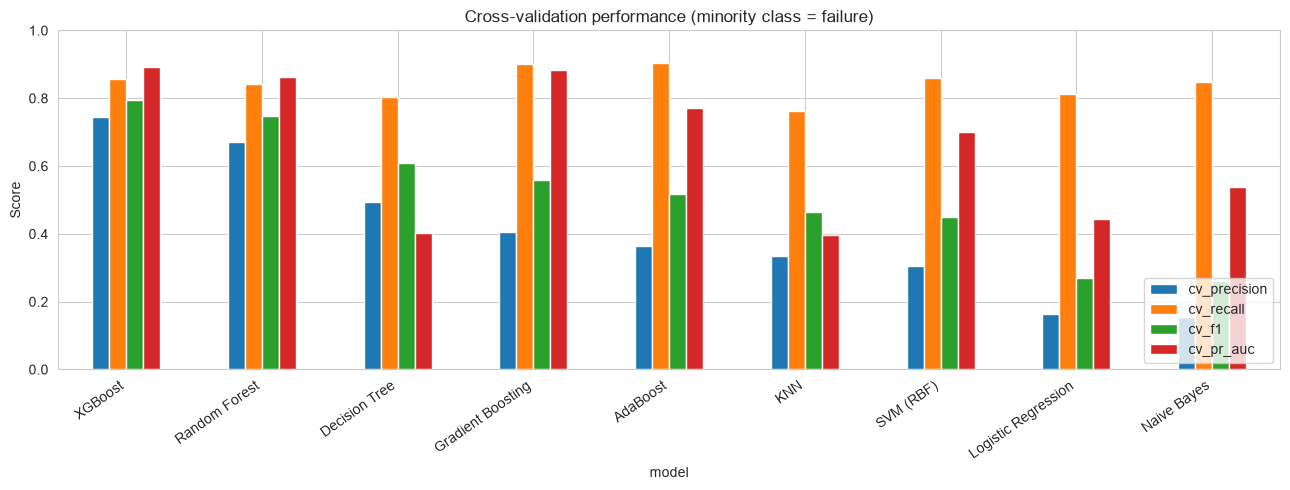

In [34]:
cv_results[['cv_precision', 'cv_recall', 'cv_f1', 'cv_pr_auc']].plot(kind='bar', figsize=(13, 5))
plt.title('Cross-validation performance (minority class = failure)')
plt.ylabel('Score'); plt.xticks(rotation=35, ha='right'); plt.ylim(0, 1)
plt.legend(loc='lower right'); plt.tight_layout(); plt.show()

Fitting the models on whole training dataset

In [35]:
def get_scores(pipe, X):
    if hasattr(pipe, 'predict_proba'):
        return pipe.predict_proba(X)[:, 1]
    return pipe.decision_function(X)

fitted = {}
test_rows = []
for name, model in models.items():
    pipe = make_pipeline(model).fit(X_train, y_train)
    fitted[name] = pipe
    pred = pipe.predict(X_test)
    score = get_scores(pipe, X_test)
    test_rows.append({'model': name,
                      'accuracy': accuracy_score(y_test, pred),
                      'precision': precision_score(y_test, pred, zero_division=0),
                      'recall': recall_score(y_test, pred),
                      'f1': f1_score(y_test, pred),
                      'roc_auc': roc_auc_score(y_test, score),
                      'pr_auc': average_precision_score(y_test, score)})

test_results = pd.DataFrame(test_rows).set_index('model').sort_values('f1', ascending=False)
test_results.round(3)

,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
XGBoost,0.979,0.651,0.824,0.727,0.980,0.867
Random Forest,0.973,0.570,0.838,0.679,0.981,0.851
Decision Tree,0.966,0.500,0.838,0.626,0.904,0.425
Gradient Boosting,0.948,0.387,0.882,0.538,0.978,0.862
AdaBoost,0.941,0.356,0.912,0.512,0.971,0.776
SVM (RBF),0.927,0.305,0.897,0.455,0.972,0.660
KNN,0.936,0.315,0.765,0.446,0.906,0.374
Logistic Regression,0.864,0.185,0.882,0.305,0.938,0.426
Naive Bayes,0.845,0.168,0.897,0.282,0.926,0.459


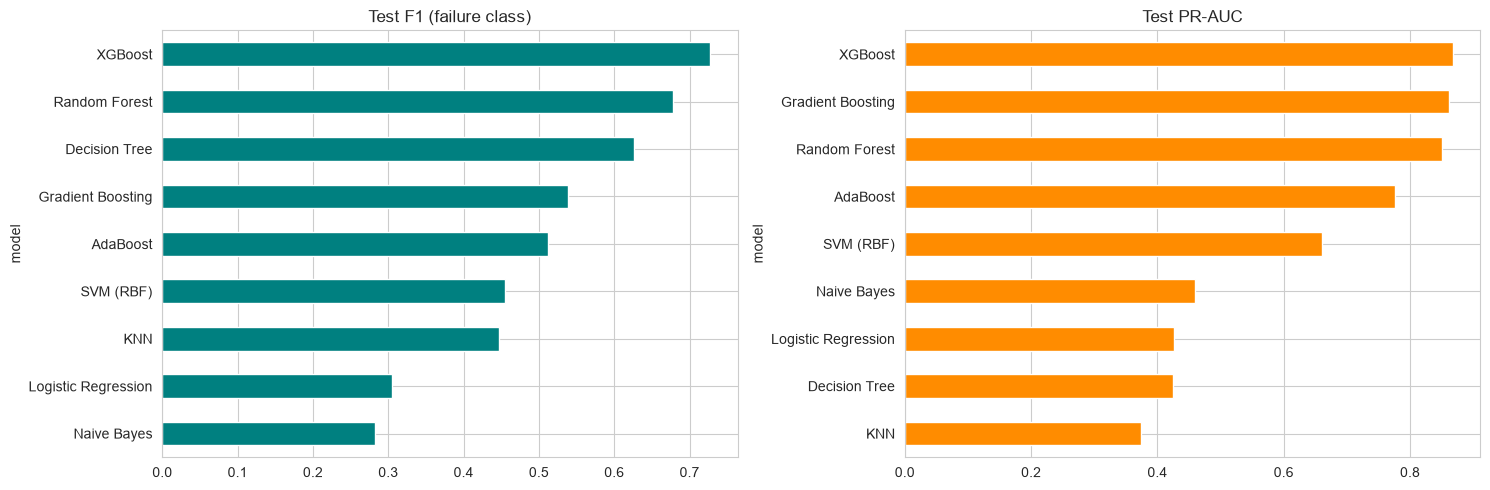

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
test_results['f1'].sort_values().plot(kind='barh', ax=axes[0], color='teal')
axes[0].set_title('Test F1 (failure class)')
test_results['pr_auc'].sort_values().plot(kind='barh', ax=axes[1], color='darkorange')
axes[1].set_title('Test PR-AUC')
plt.tight_layout(); plt.show()

## 10. Overfitting check & treatment
We compare **train F1** vs **cross-validation F1** vs **test F1**. A large gap between train and validation means the model memorised the training data and is overfitted.

In [40]:
overfit = pd.DataFrame({'train_f1': cv_results['train_f1'],
                        'cv_f1': cv_results['cv_f1'],
                        'test_f1': test_results['f1']})
overfit['gap_train_minus_test'] = overfit['train_f1'] - overfit['test_f1']
overfit['overfitting?'] = np.where(overfit['gap_train_minus_test'] > 0.10, 'YES', 'no')
overfit.sort_values('gap_train_minus_test', ascending=False).round(3)

,train_f1,cv_f1,test_f1,gap_train_minus_test,overfitting?
model,,,,,
Decision Tree,1.000,0.611,0.626,0.374,YES
Random Forest,1.000,0.746,0.679,0.321,YES
XGBoost,1.000,0.796,0.727,0.273,YES
KNN,0.621,0.464,0.446,0.175,YES
Gradient Boosting,0.625,0.559,0.538,0.087,no
SVM (RBF),0.505,0.451,0.455,0.050,no
AdaBoost,0.544,0.518,0.512,0.032,no
Naive Bayes,0.260,0.261,0.282,-0.022,no
Logistic Regression,0.279,0.270,0.305,-0.026,no


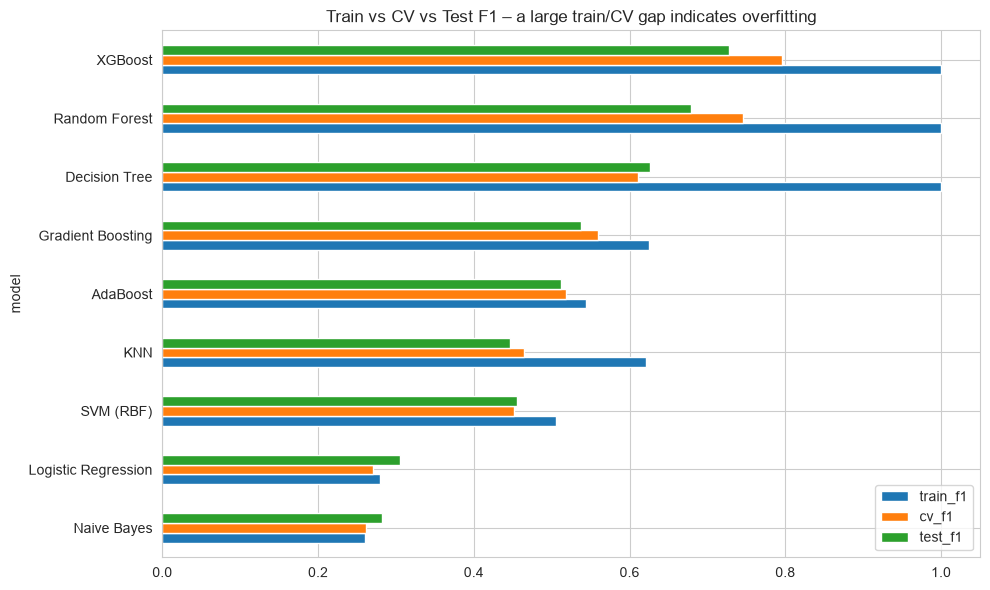

In [41]:
overfit[['train_f1', 'cv_f1', 'test_f1']].sort_values('cv_f1').plot(kind='barh', figsize=(10, 6))
plt.title('Train vs CV vs Test F1 – a large train/CV gap indicates overfitting')
plt.tight_layout(); plt.show()

### 9. Hyper-parameter tuning & overfitting check
In step 8, **XGBoost** had the best cross-validation F1, so we are tuning it using GridSearchCV.

 The settings we try in GridSearchCV:
- `max_depth`: how deep each tree can grow (smaller = simpler model)
- `n_estimators`: number of trees
- `learning_rate`: how fast the model learns (smaller = more careful)

In [43]:

from sklearn.model_selection import GridSearchCV

xgb_pipe = make_pipeline(XGBClassifier(eval_metric='logloss', random_state=RANDOM_STATE))

param_grid = {
    'model__max_depth': [3, 4, 6],
    'model__n_estimators': [300, 500],
    'model__learning_rate': [0.1, 0.2],
}

grid = GridSearchCV(xgb_pipe, param_grid, scoring='f1', cv=cv, n_jobs=-1)
grid.fit(X_train, y_train)

print('Best settings:', grid.best_params_)
print('Best cross-validation F1:', round(grid.best_score_, 3))

best_model = grid.best_estimator_

Best settings: {'model__learning_rate': 0.2, 'model__max_depth': 4, 'model__n_estimators': 300}
Best cross-validation F1: 0.809


In [45]:
# Overfitting check: compare F1 on training data vs F1 on test data
default_model = fitted['XGBoost']      # trained in step 9 with default settings

for name, model in [('Default XGBoost', default_model), ('Tuned XGBoost', best_model)]:
    train_f1 = f1_score(y_train, model.predict(X_train))
    test_f1 = f1_score(y_test, model.predict(X_test))
    print(f'{name}: train F1 = {train_f1:.3f} | test F1 = {test_f1:.3f} | gap = {train_f1 - test_f1:.3f}')

Default XGBoost: train F1 = 1.000 | test F1 = 0.727 | gap = 0.273
Tuned XGBoost: train F1 = 0.996 | test F1 = 0.775 | gap = 0.222


The train F1 is still much higher than test F1, which means the model has memorised some of the training data and is overfitted. Shallower trees (`max_depth`) and a smaller `learning_rate` make the model simpler, which is how we try to reduce this.

We choose the settings with **cross-validation on the training data**, not with the test set. The test set has only 68 failures, so its score can move up or down a little by chance. Making the model simpler is only useful if the cross-validation F1 does not get worse.

### 10. Final evaluation on the test set

In [46]:
y_pred = best_model.predict(X_test)

print('Accuracy :', round(accuracy_score(y_test, y_pred), 3))
print('Precision:', round(precision_score(y_test, y_pred), 3))
print('Recall   :', round(recall_score(y_test, y_pred), 3))
print('F1 score :', round(f1_score(y_test, y_pred), 3))
print()
print(classification_report(y_test, y_pred, target_names=['No failure', 'Failure']))

Accuracy : 0.984
Precision: 0.743
Recall   : 0.809
F1 score : 0.775

              precision    recall  f1-score   support

  No failure       0.99      0.99      0.99      1932
     Failure       0.74      0.81      0.77        68

    accuracy                           0.98      2000
   macro avg       0.87      0.90      0.88      2000
weighted avg       0.98      0.98      0.98      2000



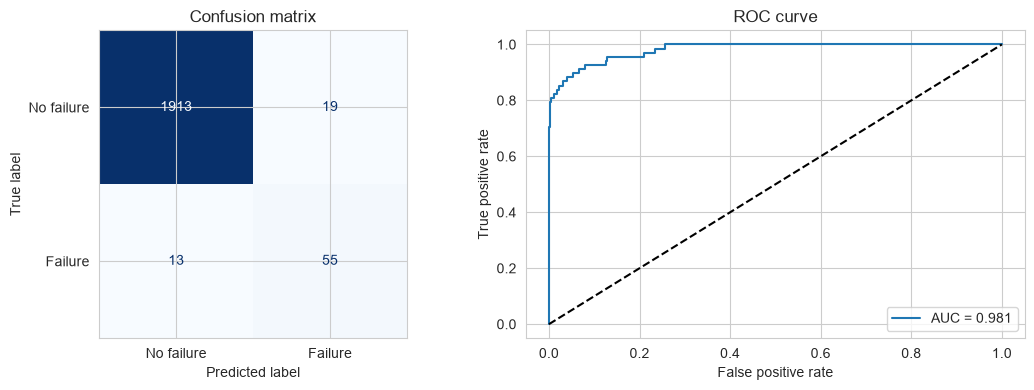

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Confusion matrix
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=['No failure', 'Failure']).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Confusion matrix')

# ROC curve
y_prob = best_model.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_test, y_prob):.3f}')
axes[1].plot([0, 1], [0, 1], 'k--')
axes[1].set_xlabel('False positive rate')
axes[1].set_ylabel('True positive rate')
axes[1].set_title('ROC curve')
axes[1].legend()

plt.tight_layout()
plt.show()

### 11. Predicting Few Values

In [54]:
sample = X_test.iloc[:5]
result = pd.DataFrame({'predicted': best_model.predict(sample),
                       'actual': y_test.iloc[:5].values})
result

,predicted,actual
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0


### 12. Conclusion

In [55]:
print('Models compared :', len(models))
print('Best model      : XGBoost (tuned)')
print('Best settings   :', grid.best_params_)
print('Test F1 score   :', round(f1_score(y_test, y_pred), 3))
print('Test recall     :', round(recall_score(y_test, y_pred), 3))
print('Test precision  :', round(precision_score(y_test, y_pred), 3))

Models compared : 9
Best model      : XGBoost (tuned)
Best settings   : {'model__learning_rate': 0.2, 'model__max_depth': 4, 'model__n_estimators': 300}
Test F1 score   : 0.775
Test recall     : 0.809
Test precision  : 0.743


### 13. Save the model for the Streamlit app

In [64]:
from sklearn.pipeline import Pipeline
import pickle

final_model = Pipeline([('scale', best_model.named_steps['scale']),
                        ('model', best_model.named_steps['model'])])

model_info = {
    'model': final_model,                          # scaler + tuned XGBoost (no SMOTE)
    'feature_columns': X_train.columns.tolist(),   # the column order the model expects
    'log_columns': skewed_cols,                    # columns where we applied log1p
}
with open('predictive_maintenance_model.pkl', 'wb') as f:
    pickle.dump(model_info, f)
print('Saved: predictive_maintenance_model.pkl')
print('Feature columns:', model_info['feature_columns'])
print('Log-transformed columns:', model_info['log_columns'])

Saved: predictive_maintenance_model.pkl
Feature columns: ['Air_temp', 'Process_temp', 'Rot_speed', 'Torque', 'Tool_wear', 'Temp_diff', 'Power', 'Torque_wear', 'Type_L', 'Type_M']
Log-transformed columns: ['Rot_speed']


In [65]:
# This function repeats steps 4, 5 and 7 for NEW raw data.
# The same function is used inside app.py.
def prepare_input(raw, feature_columns, log_columns):
    data = raw.copy()

    # step 4: feature engineering
    data['Temp_diff'] = data['Process_temp'] - data['Air_temp']
    data['Power'] = data['Torque'] * data['Rot_speed'] * 2 * np.pi / 60
    data['Torque_wear'] = data['Torque'] * data['Tool_wear']

    # step 5: log transform
    for col in log_columns:
        data[col] = np.log1p(data[col])

    # step 7: one-hot encoding of Type (Type_L, Type_M; H is the reference)
    for col in feature_columns:
        if col.startswith('Type_'):
            data[col] = (data['Type'] == col.split('_')[1]).astype(int)

    return data[feature_columns]

In [66]:
# Test: load the saved model, give it RAW data from the original file, and check that
# the result is exactly the same as what we got from the processed test data.
with open('predictive_maintenance_model.pkl', 'rb') as f:
    loaded = pickle.load(f)

raw_data = pd.read_csv("predictive_maintenance.csv").rename(columns={
    'Air temperature [K]': 'Air_temp', 'Process temperature [K]': 'Process_temp',
    'Rotational speed [rpm]': 'Rot_speed', 'Torque [Nm]': 'Torque', 'Tool wear [min]': 'Tool_wear'})
raw_test_rows = raw_data.loc[X_test.index]        # the same machines as X_test, but raw values

prepared = prepare_input(raw_test_rows, loaded['feature_columns'], loaded['log_columns'])
print('Processed data identical to X_test:', np.allclose(prepared.values, X_test.values))
print('Predictions identical             :', (loaded['model'].predict(prepared) == best_model.predict(X_test)).all())

# Example: one new machine typed in by a user
new_machine = pd.DataFrame([{'Type': 'L', 'Air_temp': 300.0, 'Process_temp': 310.0,
                             'Rot_speed': 1400, 'Torque': 65.0, 'Tool_wear': 200}])
x_new = prepare_input(new_machine, loaded['feature_columns'], loaded['log_columns'])
print('Failure probability for the new machine: %.1f%%' % (loaded['model'].predict_proba(x_new)[0, 1] * 100))

Processed data identical to X_test: True
Predictions identical             : True
Failure probability for the new machine: 100.0%
